# Red neuronal de tres capas ocultas con TensorFlow + Keras
---

**Universidad de Cundinamarca**

**CADI:** Deep Learning — Conceptos
**Estudiante:** Ruby Dayana Cárdenas Gómez
**Docente:** Nidia Stella García Roa
**Fecha:** Octubre de 2026

---
En este cuaderno construyo una red neuronal densa con **tres capas ocultas** para clasificar prendas de ropa (Fashion-MNIST), dibujo la arquitectura para ver cómo se conectan las capas, la entreno y analizo los resultados.

## 1. Librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(42)   # para que los resultados sean reproducibles
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1


## 2. Los datos: Fashion-MNIST

70 000 imágenes en escala de grises de 28 × 28 píxeles, repartidas en 10 clases de prendas. Cada imagen se convierte en un vector de 784 números (28 × 28) y los píxeles se escalan de 0-255 a 0-1 para que la red entrene de forma estable.

In [2]:
(X_ent, Y_ent), (X_pru, Y_pru) = keras.datasets.fashion_mnist.load_data()
CLASES = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo", "Sandalia", "Camisa", "Tenis", "Bolso", "Bota"]

# Aplanar y escalar
X_ent = X_ent.reshape(-1, 784).astype("float32") / 255.0
X_pru = X_pru.reshape(-1, 784).astype("float32") / 255.0

# Separo 10 000 imágenes de entrenamiento para validación
X_val, Y_val = X_ent[:10000], Y_ent[:10000]
X_ent, Y_ent = X_ent[10000:], Y_ent[10000:]

print("Entrenamiento:", X_ent.shape, "| Validación:", X_val.shape, "| Prueba:", X_pru.shape)

Entrenamiento: (50000, 784) | Validación: (10000, 784) | Prueba: (10000, 784)


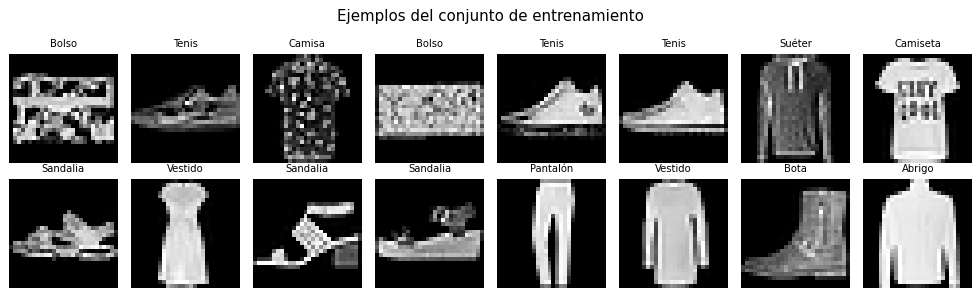

In [3]:
fig, ejes = plt.subplots(2, 8, figsize=(11, 3.4))
for i, eje in enumerate(ejes.ravel()):
    eje.imshow(X_ent[i].reshape(28, 28), cmap="gray")
    eje.set_title(CLASES[Y_ent[i]], fontsize=8); eje.axis("off")
plt.suptitle("Ejemplos del conjunto de entrenamiento"); plt.tight_layout(); plt.show()

## 3. Arquitectura de la red

| Capa | Neuronas | Activación | Qué hace |
|---|---|---|---|
| Entrada | 784 | — | Recibe los 784 píxeles de la imagen |
| Oculta 1 | 128 | ReLU | Combina píxeles y detecta patrones simples (bordes, manchas) |
| Oculta 2 | 64 | ReLU | Combina los patrones anteriores en formas más complejas |
| Oculta 3 | 32 | ReLU | Resume la información en pocas características |
| Salida | 10 | Softmax | Entrega la probabilidad de cada una de las 10 prendas |

Cada neurona de una capa está conectada con **todas** las neuronas de la siguiente (por eso se llaman capas densas). Cada conexión tiene un peso que la red ajusta durante el entrenamiento.

In [4]:
modelo = keras.Sequential([
    keras.layers.Input(shape=(784,), name="entrada"),
    keras.layers.Dense(128, activation="relu", name="oculta_1"),
    keras.layers.Dense(64, activation="relu", name="oculta_2"),
    keras.layers.Dense(32, activation="relu", name="oculta_3"),
    keras.layers.Dense(10, activation="softmax", name="salida"),
], name="red_tres_capas")

modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
modelo.summary()

Model: "red_tres_capas"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 111,146 (434.16 KB)
 Trainable params: 111,146 (434.16 KB)
 Non-trainable params: 0 (0.00 B)


### 3.1. ¿De dónde salen los parámetros?

Cada capa densa tiene `entradas × neuronas` pesos más `neuronas` sesgos:

- Oculta 1: 784 × 128 + 128 = **100 480**
- Oculta 2: 128 × 64 + 64 = **8 256**
- Oculta 3: 64 × 32 + 32 = **2 080**
- Salida: 32 × 10 + 10 = **330**

En total 111 146 parámetros que la red aprende.

### 3.2. Gráfica de la relación entre las capas

Dibujo la red con un nodo por neurona (mostrando solo algunas por capa para que se pueda ver) y las conexiones entre capas consecutivas. El grosor de la flecha general indica cuántos pesos conectan cada par de capas.

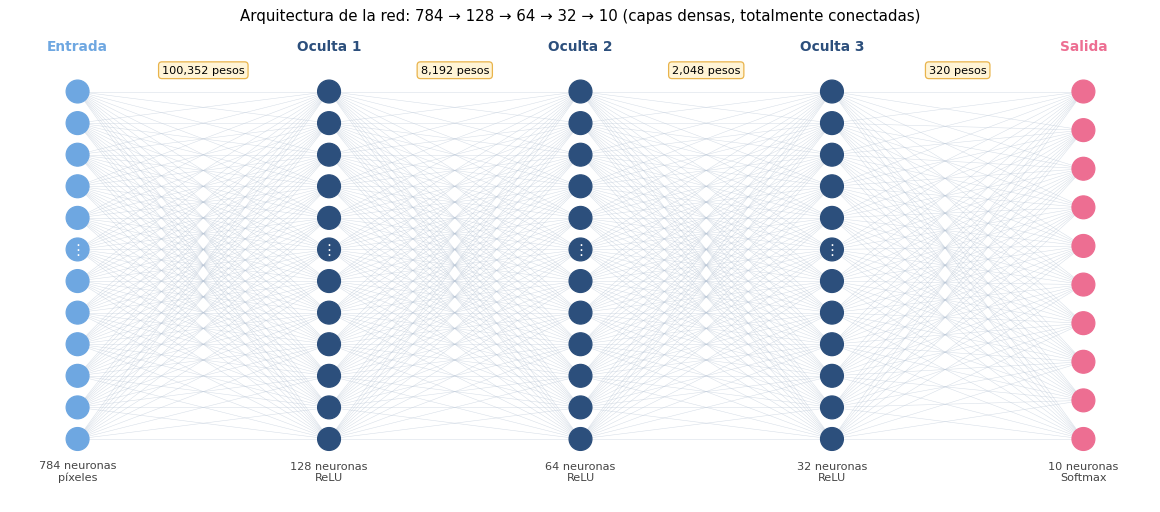

In [5]:
def dibujar_red(capas, nombres, activaciones, mostrar_max=12):
    """Dibuja una red densa: cada columna es una capa y cada círculo una neurona (se muestran como máximo mostrar_max)."""
    fig, ax = plt.subplots(figsize=(13, 6.5))
    colores = ["#6EA7E1", "#2C4F7C", "#2C4F7C", "#2C4F7C", "#ED6E92"]
    xs = np.linspace(0, 2.2, len(capas))
    posiciones = []
    for i, (n, x) in enumerate(zip(capas, xs)):
        k = min(n, mostrar_max)
        ys = np.linspace(0.12, 0.88, k)
        posiciones.append(ys)
        for j, y in enumerate(ys):
            ax.add_patch(plt.Circle((x, y), 0.025, color=colores[i], zorder=3))
            if n > mostrar_max and j == k // 2:          # marca de "hay más neuronas"
                ax.text(x, y, "⋮", ha="center", va="center", color="white", fontsize=12, zorder=4)
        ax.text(x, 0.97, nombres[i], ha="center", fontsize=11, weight="bold", color=colores[i])
        ax.text(x, 0.03, f"{n} neuronas\n{activaciones[i]}", ha="center", fontsize=9, color="#444")
    # conexiones entre capas consecutivas
    for i in range(len(capas) - 1):
        pesos = capas[i] * capas[i + 1]
        for y1 in posiciones[i]:
            for y2 in posiciones[i + 1]:
                ax.plot([xs[i], xs[i + 1]], [y1, y2], color="#B9C6D6", lw=0.4, alpha=0.6, zorder=1)
        ax.annotate(f"{pesos:,} pesos", xy=((xs[i] + xs[i + 1]) / 2, 0.92), ha="center", fontsize=9,
                    bbox=dict(boxstyle="round,pad=0.3", fc="#FFF4D6", ec="#E9B44C"))
    ax.set_xlim(-0.15, 2.35); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Arquitectura de la red: 784 → 128 → 64 → 32 → 10 (capas densas, totalmente conectadas)", fontsize=12)
    plt.tight_layout(); plt.show()

dibujar_red([784, 128, 64, 32, 10],
            ["Entrada", "Oculta 1", "Oculta 2", "Oculta 3", "Salida"],
            ["píxeles", "ReLU", "ReLU", "ReLU", "Softmax"])

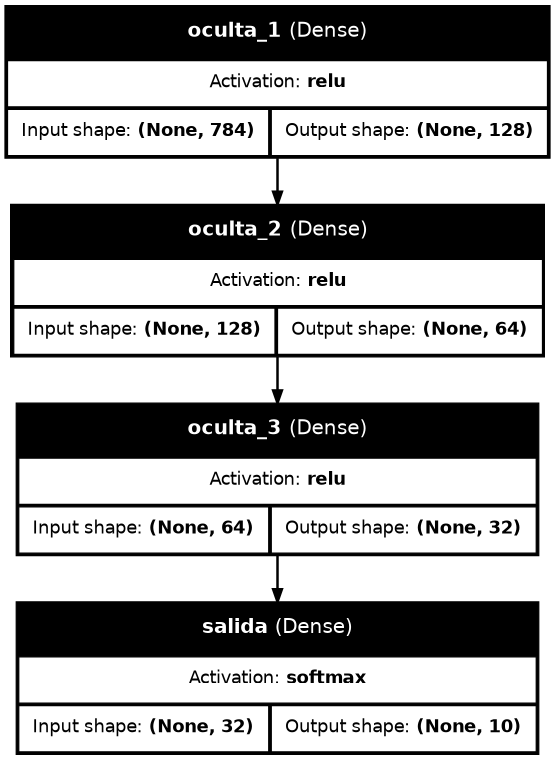

In [6]:
# La misma arquitectura dibujada por Keras (bloques con la forma de entrada y salida de cada capa)
keras.utils.plot_model(modelo, to_file="arquitectura_keras.png", show_shapes=True, show_layer_names=True, show_layer_activations=True, dpi=90)
from IPython.display import Image, display
display(Image("arquitectura_keras.png"))

## 4. Entrenamiento

Entreno 20 épocas con lotes de 128 imágenes, vigilando el conjunto de validación. Uso *Early Stopping* para detenerme si el error de validación deja de mejorar y quedarme con los mejores pesos.

In [7]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

historia = modelo.fit(X_ent, Y_ent,
                      validation_data=(X_val, Y_val),
                      epochs=20, batch_size=128,
                      callbacks=[parada], verbose=2)

Epoch 1/20
391/391 - 3s - 7ms/step - accuracy: 0.7954 - loss: 0.5985 - val_accuracy: 0.8275 - val_loss: 0.4782
Epoch 2/20
391/391 - 2s - 6ms/step - accuracy: 0.8555 - loss: 0.4051 - val_accuracy: 0.8460 - val_loss: 0.4253
Epoch 3/20
391/391 - 1s - 3ms/step - accuracy: 0.8687 - loss: 0.3596 - val_accuracy: 0.8491 - val_loss: 0.4125
Epoch 4/20
391/391 - 1s - 3ms/step - accuracy: 0.8780 - loss: 0.3338 - val_accuracy: 0.8549 - val_loss: 0.3961
Epoch 5/20
391/391 - 1s - 4ms/step - accuracy: 0.8845 - loss: 0.3143 - val_accuracy: 0.8646 - val_loss: 0.3677
Epoch 6/20
391/391 - 3s - 6ms/step - accuracy: 0.8900 - loss: 0.2980 - val_accuracy: 0.8668 - val_loss: 0.3541
Epoch 7/20
391/391 - 3s - 7ms/step - accuracy: 0.8936 - loss: 0.2866 - val_accuracy: 0.8734 - val_loss: 0.3401
Epoch 8/20
391/391 - 2s - 6ms/step - accuracy: 0.8980 - loss: 0.2745 - val_accuracy: 0.8769 - val_loss: 0.3309
Epoch 9/20
391/391 - 1s - 4ms/step - accuracy: 0.9025 - loss: 0.2630 - val_accuracy: 0.8798 - val_loss: 0.3320
E

Épocas entrenadas: 14
Mejor exactitud en validación: 88.35 %


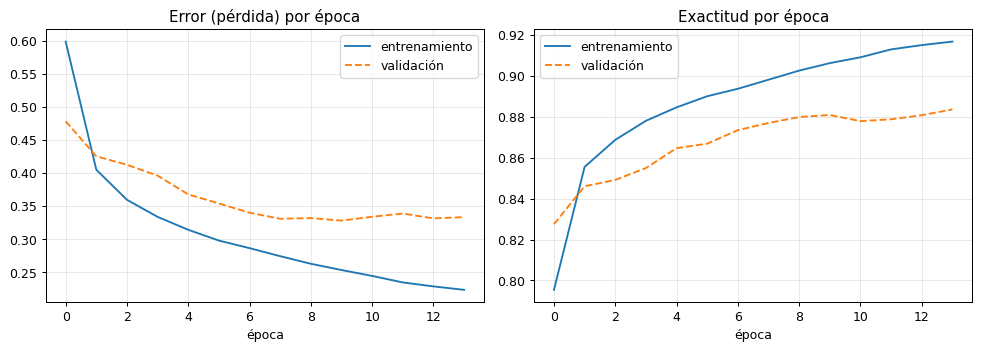

In [8]:
h = historia.history
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(h["loss"], label="entrenamiento"); ejes[0].plot(h["val_loss"], "--", label="validación")
ejes[0].set_title("Error (pérdida) por época"); ejes[0].set_xlabel("época"); ejes[0].legend(); ejes[0].grid(alpha=0.3)
ejes[1].plot(h["accuracy"], label="entrenamiento"); ejes[1].plot(h["val_accuracy"], "--", label="validación")
ejes[1].set_title("Exactitud por época"); ejes[1].set_xlabel("época"); ejes[1].legend(); ejes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Épocas entrenadas: {len(h['loss'])}")
print(f"Mejor exactitud en validación: {max(h['val_accuracy'])*100:.2f} %")

## 5. Evaluación en el conjunto de prueba
Estas 10 000 imágenes nunca se usaron para entrenar ni para ajustar la red.

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

perdida, exactitud = modelo.evaluate(X_pru, Y_pru, verbose=0)
print(f"Exactitud en prueba: {exactitud*100:.2f} %   |   Pérdida: {perdida:.4f}\n")

predicciones = np.argmax(modelo.predict(X_pru, verbose=0), axis=1)
print(classification_report(Y_pru, predicciones, target_names=CLASES, digits=3))

Exactitud en prueba: 87.26 %   |   Pérdida: 0.3566

              precision    recall  f1-score   support

    Camiseta      0.835     0.823     0.829      1000
    Pantalón      0.993     0.965     0.979      1000
      Suéter      0.878     0.649     0.746      1000
     Vestido      0.878     0.886     0.882      1000
      Abrigo      0.747     0.830     0.786      1000
    Sandalia      0.977     0.940     0.958      1000
      Camisa      0.642     0.744     0.690      1000
       Tenis      0.943     0.945     0.944      1000
       Bolso      0.960     0.972     0.966      1000
        Bota      0.927     0.972     0.949      1000

    accuracy                          0.873     10000
   macro avg      0.878     0.873     0.873     10000
weighted avg      0.878     0.873     0.873     10000



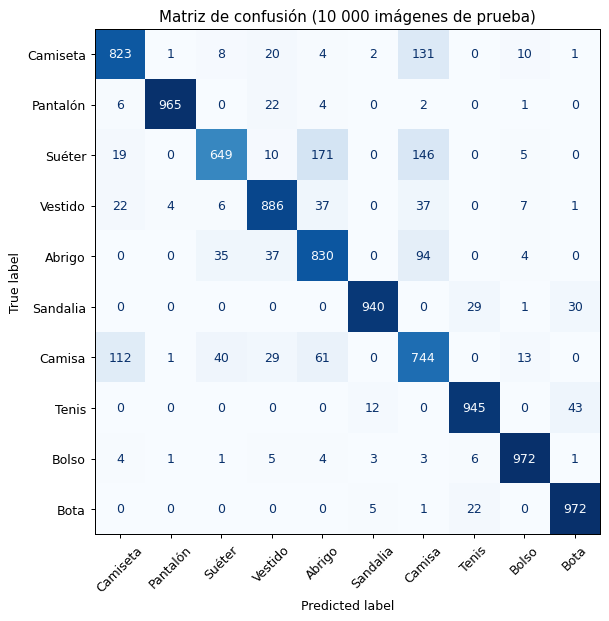

In [10]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(Y_pru, predicciones), display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Matriz de confusión (10 000 imágenes de prueba)"); plt.tight_layout(); plt.show()

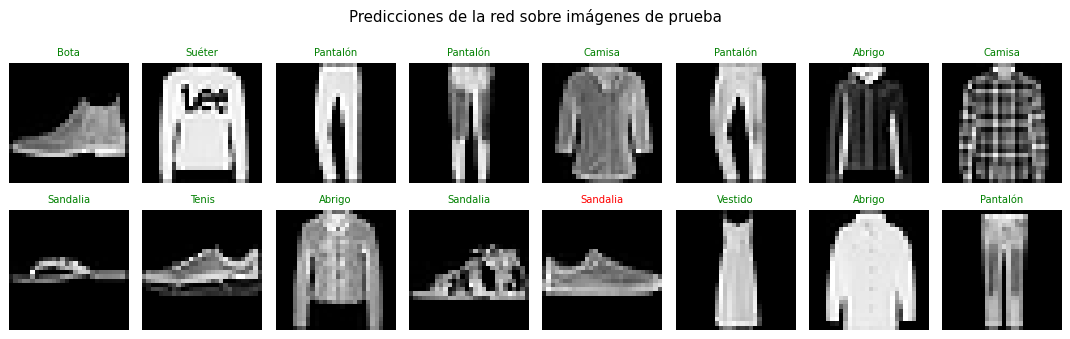

In [11]:
# Algunas predicciones: verde = acierto, rojo = error
fig, ejes = plt.subplots(2, 8, figsize=(12, 4))
for i, eje in enumerate(ejes.ravel()):
    eje.imshow(X_pru[i].reshape(28, 28), cmap="gray")
    ok = predicciones[i] == Y_pru[i]
    eje.set_title(f"{CLASES[predicciones[i]]}", fontsize=8, color="green" if ok else "red"); eje.axis("off")
plt.suptitle("Predicciones de la red sobre imágenes de prueba"); plt.tight_layout(); plt.show()

## 6. ¿Qué “ve” cada capa?

Tomo una imagen y miro las activaciones de las tres capas ocultas: cuántas neuronas se encienden y con qué intensidad. Así se aprecia cómo la información se va comprimiendo de 784 valores a 128, 64 y 32.

Neuronas activas (> 0) por capa oculta: [60, 34, 15]
Predicción: Bota con probabilidad 99.4 %


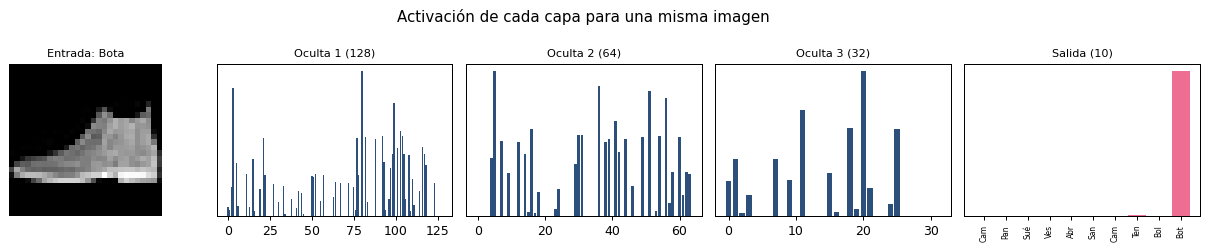

In [12]:
extractor = keras.Model(inputs=modelo.inputs, outputs=[capa.output for capa in modelo.layers])
activaciones = extractor.predict(X_pru[:1], verbose=0)

fig, ejes = plt.subplots(1, 5, figsize=(14, 2.8))
ejes[0].imshow(X_pru[0].reshape(28, 28), cmap="gray"); ejes[0].set_title(f"Entrada: {CLASES[Y_pru[0]]}", fontsize=9); ejes[0].axis("off")
for i, (act, nombre) in enumerate(zip(activaciones, ["Oculta 1 (128)", "Oculta 2 (64)", "Oculta 3 (32)", "Salida (10)"]), 1):
    ejes[i].bar(range(act.shape[1]), act[0], color="#2C4F7C" if i < 4 else "#ED6E92")
    ejes[i].set_title(nombre, fontsize=9); ejes[i].set_yticks([])
    if i == 4: ejes[i].set_xticks(range(10)); ejes[i].set_xticklabels([c[:3] for c in CLASES], fontsize=6, rotation=90)
plt.suptitle("Activación de cada capa para una misma imagen"); plt.tight_layout(); plt.show()
print("Neuronas activas (> 0) por capa oculta:", [int((a[0] > 0).sum()) for a in activaciones[:3]])
print("Predicción:", CLASES[int(np.argmax(activaciones[3][0]))], f"con probabilidad {activaciones[3][0].max()*100:.1f} %")

## 7. Conclusiones

*(Las conclusiones completas están en el informe; aquí el resumen.)*

- La red de tres capas ocultas (784 → 128 → 64 → 32 → 10, 111 146 parámetros) clasifica correctamente cerca del 88-89 % de las prendas de prueba.
- Las curvas muestran que después de pocas épocas la exactitud de validación se estabiliza mientras la de entrenamiento sigue subiendo: la red empieza a memorizar y el Early Stopping evita entrenar de más.
- Cada capa comprime la información: de 784 píxeles a 32 características antes de la decisión final. Las confusiones se concentran entre prendas parecidas (camisa, camiseta, suéter, abrigo).